In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors
from rdkit.Chem import rdFingerprintGenerator
from rdkit import DataStructs

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr

import matplotlib.pyplot as plt

DATA_PATH = Path("../data/raw/oedb_electrolytes_v2026_05_11.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (5616, 20)


,ID,exp-ID,Cation,Anion,Solvent,Concentration (mol/kg),Ionic Conductivity (mS/cm),Viscosity (mPa·s),Cation's Diffusivity (m²/s),Anion's Diffusivity (m²/s),Solvent's Diffusivity (m²/s),Coordination (Cation←Anion),Coordination (Cation ← Solvent),Density (g/cm³),Anion SMILES,Solvent SMILES,Anion PubChem CID,Solvent PubChem CID,x,y
0,1,NaN,K,BETI,AN,0.5,18.348073,0.320151,1.280000e-09,1.090000e-09,2.510000e-09,0.177195,6.482342,0.850743,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-60.781920,-21.211819
1,2,NaN,K,BETI,AN,1.0,40.029239,0.778737,1.230000e-09,7.410000e-10,2.110000e-09,0.332376,6.218885,0.933113,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-60.421020,-20.695742
2,3,NaN,K,BETI,AN,1.5,28.589258,0.834437,1.090000e-09,6.840000e-10,1.830000e-09,0.473627,6.034723,1.000746,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-59.876976,-19.905375
3,4,NaN,K,BETI,AN,2.0,28.614872,1.298528,7.870000e-10,5.880000e-10,1.470000e-09,0.590422,5.873371,1.066779,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-59.369880,-19.195618
4,5,NaN,K,BETI,AN,2.5,37.791487,1.086047,6.760000e-10,4.690000e-10,1.200000e-09,0.741233,5.662183,1.120867,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-58.683660,-18.369247


In [2]:
df_clean = df.rename(columns={
    "ID": "id",
    "exp-ID": "exp_id",
    "Cation": "cation",
    "Anion": "anion",
    "Solvent": "solvent",
    "Concentration (mol/kg)": "concentration_mol_kg",
    "Ionic Conductivity (mS/cm)": "ionic_conductivity_ms_cm",
    "Viscosity (mPa·s)": "viscosity_mpa_s",
    "Cation's Diffusivity (m²/s)": "cation_diffusivity_m2_s",
    "Anion's Diffusivity (m²/s)": "anion_diffusivity_m2_s",
    "Solvent's Diffusivity (m²/s)": "solvent_diffusivity_m2_s",
    "Coordination (Cation←Anion)": "coordination_cation_anion",
    "Coordination (Cation ← Solvent)": "coordination_cation_solvent",
    "Density (g/cm³)": "density_g_cm3",
    "Anion SMILES": "anion_smiles",
    "Solvent SMILES": "solvent_smiles",
    "Anion PubChem CID": "anion_pubchem_cid",
    "Solvent PubChem CID": "solvent_pubchem_cid",
    "x": "tsne_x",
    "y": "tsne_y"
})

data = df_clean[[
    "id",
    "cation",
    "anion",
    "solvent",
    "concentration_mol_kg",
    "ionic_conductivity_ms_cm",
    "anion_smiles",
    "solvent_smiles"
]].copy()

data = data.dropna(subset=[
    "ionic_conductivity_ms_cm",
    "anion_smiles",
    "solvent_smiles"
]).copy()

print("Model data shape:", data.shape)
display(data.head())

Model data shape: (5595, 8)


,id,cation,anion,solvent,concentration_mol_kg,ionic_conductivity_ms_cm,anion_smiles,solvent_smiles
0,1,K,BETI,AN,0.5,18.348073,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N
1,2,K,BETI,AN,1.0,40.029239,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N
2,3,K,BETI,AN,1.5,28.589258,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N
3,4,K,BETI,AN,2.0,28.614872,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N
4,5,K,BETI,AN,2.5,37.791487,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N


In [3]:
# Add small epsilon to avoid log10(0)
epsilon = 1e-6

data["log_conductivity"] = np.log10(data["ionic_conductivity_ms_cm"] + epsilon)

print("Raw conductivity range:")
print(data["ionic_conductivity_ms_cm"].describe())

print("\nLog conductivity range:")
print(data["log_conductivity"].describe())

Raw conductivity range:
count    5595.000000
mean        6.135086
std        12.750394
min         0.000126
25%         0.404781
50%         1.641149
75%         5.078750
max       127.109335
Name: ionic_conductivity_ms_cm, dtype: float64

Log conductivity range:
count    5595.000000
mean        0.126933
std         0.873843
min        -3.897189
25%        -0.392779
50%         0.215148
75%         0.705757
max         2.104177
Name: log_conductivity, dtype: float64


In [4]:
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)

def smiles_to_morgan_array(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")
    
    fp = morgan_generator.GetFingerprint(mol)
    arr = np.zeros((1024,), dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

In [5]:
def count_atom(mol, symbol):
    return sum(1 for atom in mol.GetAtoms() if atom.GetSymbol() == symbol)

def smiles_to_descriptors(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")

    descriptors = {
        "mol_wt": Descriptors.MolWt(mol),
        "exact_mol_wt": Descriptors.ExactMolWt(mol),
        "tpsa": Descriptors.TPSA(mol),
        "num_h_acceptors": Descriptors.NumHAcceptors(mol),
        "num_h_donors": Descriptors.NumHDonors(mol),
        "num_rotatable_bonds": Descriptors.NumRotatableBonds(mol),
        "ring_count": rdMolDescriptors.CalcNumRings(mol),
        "heavy_atom_count": Descriptors.HeavyAtomCount(mol),
        "num_hetero_atoms": rdMolDescriptors.CalcNumHeteroatoms(mol),
        "formal_charge": Chem.GetFormalCharge(mol),
        "num_f_atoms": count_atom(mol, "F"),
        "num_o_atoms": count_atom(mol, "O"),
        "num_n_atoms": count_atom(mol, "N"),
        "num_s_atoms": count_atom(mol, "S"),
    }

    return descriptors

In [6]:
anion_fps = np.vstack(data["anion_smiles"].apply(smiles_to_morgan_array).values)
solvent_fps = np.vstack(data["solvent_smiles"].apply(smiles_to_morgan_array).values)

anion_desc = pd.DataFrame(
    data["anion_smiles"].apply(smiles_to_descriptors).tolist()
).add_prefix("anion_")

solvent_desc = pd.DataFrame(
    data["solvent_smiles"].apply(smiles_to_descriptors).tolist()
).add_prefix("solvent_")

print("Anion fingerprint shape:", anion_fps.shape)
print("Solvent fingerprint shape:", solvent_fps.shape)
print("Anion descriptor shape:", anion_desc.shape)
print("Solvent descriptor shape:", solvent_desc.shape)

display(anion_desc.head())
display(solvent_desc.head())

Anion fingerprint shape: (5595, 1024)
Solvent fingerprint shape: (5595, 1024)
Anion descriptor shape: (5595, 14)
Solvent descriptor shape: (5595, 14)


,anion_mol_wt,anion_exact_mol_wt,anion_tpsa,anion_num_h_acceptors,anion_num_h_donors,anion_num_rotatable_bonds,anion_ring_count,anion_heavy_atom_count,anion_num_hetero_atoms,anion_formal_charge,anion_num_f_atoms,anion_num_o_atoms,anion_num_n_atoms,anion_num_s_atoms
0,380.161,379.911455,82.38,4,0,4,0,21,17,-1,10,4,1,2
1,380.161,379.911455,82.38,4,0,4,0,21,17,-1,10,4,1,2
2,380.161,379.911455,82.38,4,0,4,0,21,17,-1,10,4,1,2
3,380.161,379.911455,82.38,4,0,4,0,21,17,-1,10,4,1,2
4,380.161,379.911455,82.38,4,0,4,0,21,17,-1,10,4,1,2


,solvent_mol_wt,solvent_exact_mol_wt,solvent_tpsa,solvent_num_h_acceptors,solvent_num_h_donors,solvent_num_rotatable_bonds,solvent_ring_count,solvent_heavy_atom_count,solvent_num_hetero_atoms,solvent_formal_charge,solvent_num_f_atoms,solvent_num_o_atoms,solvent_num_n_atoms,solvent_num_s_atoms
0,41.053,41.026549,23.79,1,0,0,0,3,1,0,0,0,1,0
1,41.053,41.026549,23.79,1,0,0,0,3,1,0,0,0,1,0
2,41.053,41.026549,23.79,1,0,0,0,3,1,0,0,0,1,0
3,41.053,41.026549,23.79,1,0,0,0,3,1,0,0,0,1,0
4,41.053,41.026549,23.79,1,0,0,0,3,1,0,0,0,1,0


In [7]:
cation_onehot = pd.get_dummies(data["cation"], prefix="cation").astype(int)

numeric_features = pd.concat([
    data[["concentration_mol_kg"]].reset_index(drop=True),
    cation_onehot.reset_index(drop=True),
    anion_desc.reset_index(drop=True),
    solvent_desc.reset_index(drop=True)
], axis=1)

X_improved = np.hstack([
    anion_fps,
    solvent_fps,
    numeric_features.values
])

y_raw = data["ionic_conductivity_ms_cm"].values
y_log = data["log_conductivity"].values

print("Improved feature matrix shape:", X_improved.shape)
print("Raw target shape:", y_raw.shape)
print("Log target shape:", y_log.shape)
print("Extra numeric feature columns:")
print(numeric_features.columns.tolist())

Improved feature matrix shape: (5595, 2080)
Raw target shape: (5595,)
Log target shape: (5595,)
Extra numeric feature columns:
['concentration_mol_kg', 'cation_K', 'cation_Li', 'cation_Na', 'anion_mol_wt', 'anion_exact_mol_wt', 'anion_tpsa', 'anion_num_h_acceptors', 'anion_num_h_donors', 'anion_num_rotatable_bonds', 'anion_ring_count', 'anion_heavy_atom_count', 'anion_num_hetero_atoms', 'anion_formal_charge', 'anion_num_f_atoms', 'anion_num_o_atoms', 'anion_num_n_atoms', 'anion_num_s_atoms', 'solvent_mol_wt', 'solvent_exact_mol_wt', 'solvent_tpsa', 'solvent_num_h_acceptors', 'solvent_num_h_donors', 'solvent_num_rotatable_bonds', 'solvent_ring_count', 'solvent_heavy_atom_count', 'solvent_num_hetero_atoms', 'solvent_formal_charge', 'solvent_num_f_atoms', 'solvent_num_o_atoms', 'solvent_num_n_atoms', 'solvent_num_s_atoms']


In [8]:
def evaluate_model(model, X_train, X_test, y_train_log, y_test_raw):
    model.fit(X_train, y_train_log)
    
    pred_log = model.predict(X_test)
    
    # Convert log prediction back to original conductivity scale
    pred_raw = (10 ** pred_log) - epsilon
    
    mae = mean_absolute_error(y_test_raw, pred_raw)
    rmse = np.sqrt(mean_squared_error(y_test_raw, pred_raw))
    r2 = r2_score(y_test_raw, pred_raw)
    spearman = spearmanr(y_test_raw, pred_raw).correlation
    
    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Spearman": spearman
    }, pred_raw

In [9]:
indices = np.arange(len(data))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42
)

X_train = X_improved[train_idx]
X_test = X_improved[test_idx]

y_train_log = y_log[train_idx]
y_test_raw = y_raw[test_idx]

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

random_results = []

for name, model in models.items():
    metrics, preds = evaluate_model(model, X_train, X_test, y_train_log, y_test_raw)
    metrics["Model"] = name
    metrics["Validation"] = "Random split"
    random_results.append(metrics)

random_results_df = pd.DataFrame(random_results)
random_results_df = random_results_df[["Validation", "Model", "MAE", "RMSE", "R2", "Spearman"]]

display(random_results_df)

,Validation,Model,MAE,RMSE,R2,Spearman
0,Random split,Random Forest,2.001895,5.576282,0.789346,0.962890
1,Random split,Extra Trees,2.142166,6.086243,0.749055,0.960269
2,Random split,Gradient Boosting,2.342154,6.015902,0.754822,0.922004


In [10]:
groups = data["solvent"].values

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

for train_idx_group, test_idx_group in gss.split(X_improved, y_raw, groups=groups):
    X_train_group = X_improved[train_idx_group]
    X_test_group = X_improved[test_idx_group]

    y_train_group_log = y_log[train_idx_group]
    y_test_group_raw = y_raw[test_idx_group]

    heldout_solvents = sorted(data.iloc[test_idx_group]["solvent"].unique())
    print("Held-out solvents:", heldout_solvents)

    solvent_results = []

    for name, model in models.items():
        metrics, preds = evaluate_model(
            model,
            X_train_group,
            X_test_group,
            y_train_group_log,
            y_test_group_raw
        )
        metrics["Model"] = name
        metrics["Validation"] = "Solvent-held-out"
        solvent_results.append(metrics)

solvent_results_df = pd.DataFrame(solvent_results)
solvent_results_df = solvent_results_df[["Validation", "Model", "MAE", "RMSE", "R2", "Spearman"]]

display(solvent_results_df)

Held-out solvents: ['AN', 'EA', 'EB', 'EMC', 'FEMC', 'TEP']


,Validation,Model,MAE,RMSE,R2,Spearman
0,Solvent-held-out,Random Forest,3.863564,9.758071,0.685697,0.626524
1,Solvent-held-out,Extra Trees,3.630119,9.312963,0.713716,0.647309
2,Solvent-held-out,Gradient Boosting,4.800078,12.963335,0.445305,0.618360


In [11]:
all_results_df = pd.concat(
    [random_results_df, solvent_results_df],
    ignore_index=True
)

display(all_results_df)

all_results_df.to_csv(
    "../outputs/metrics/improved_model_comparison.csv",
    index=False
)

,Validation,Model,MAE,RMSE,R2,Spearman
0,Random split,Random Forest,2.001895,5.576282,0.789346,0.962890
1,Random split,Extra Trees,2.142166,6.086243,0.749055,0.960269
2,Random split,Gradient Boosting,2.342154,6.015902,0.754822,0.922004
3,Solvent-held-out,Random Forest,3.863564,9.758071,0.685697,0.626524
4,Solvent-held-out,Extra Trees,3.630119,9.312963,0.713716,0.647309
5,Solvent-held-out,Gradient Boosting,4.800078,12.963335,0.445305,0.618360


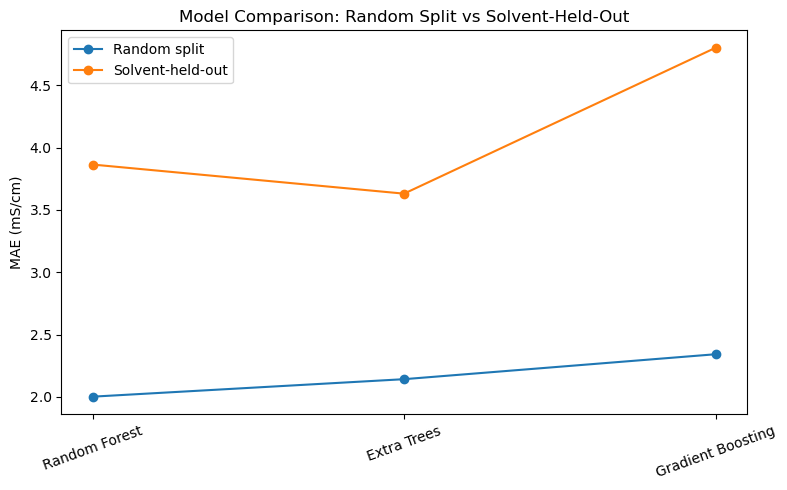

In [12]:
plt.figure(figsize=(8, 5))

for validation_type in all_results_df["Validation"].unique():
    subset = all_results_df[all_results_df["Validation"] == validation_type]
    plt.plot(
        subset["Model"],
        subset["MAE"],
        marker="o",
        label=validation_type
    )

plt.ylabel("MAE (mS/cm)")
plt.title("Model Comparison: Random Split vs Solvent-Held-Out")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()

plt.savefig("../outputs/figures/improved_model_mae_comparison.png", dpi=300)
plt.show()

In [13]:
baseline_vs_improved = pd.DataFrame([
    {
        "Stage": "Baseline RF",
        "Features": "Morgan fingerprints + cation + concentration",
        "Target": "Raw conductivity",
        "Validation": "Solvent-held-out",
        "Best_Model": "Random Forest",
        "MAE": 7.549,
        "RMSE": 18.522,
        "R2": -0.132,
        "Spearman": 0.244
    },
    {
        "Stage": "Improved model",
        "Features": "Morgan fingerprints + RDKit descriptors + cation + concentration",
        "Target": "Log conductivity",
        "Validation": "Solvent-held-out",
        "Best_Model": "Extra Trees",
        "MAE": 3.630,
        "RMSE": 9.313,
        "R2": 0.714,
        "Spearman": 0.647
    }
])

display(baseline_vs_improved)

baseline_vs_improved.to_csv(
    "../outputs/metrics/baseline_vs_improved_comparison.csv",
    index=False
)

,Stage,Features,Target,Validation,Best_Model,MAE,RMSE,R2,Spearman
0,Baseline RF,Morgan fingerprints + cation + concentration,Raw conductivity,Solvent-held-out,Random Forest,7.549,18.522,-0.132,0.244
1,Improved model,Morgan fingerprints + RDKit descriptors + cati...,Log conductivity,Solvent-held-out,Extra Trees,3.630,9.313,0.714,0.647


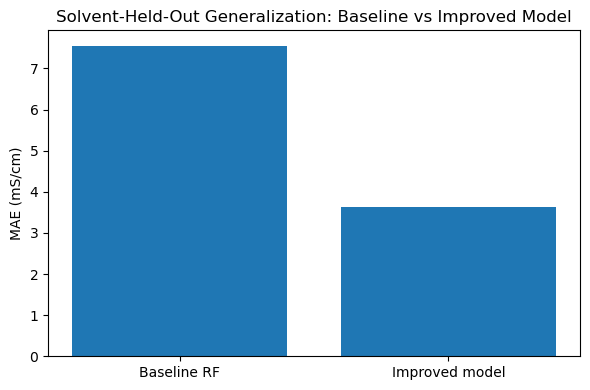

In [14]:
plt.figure(figsize=(6, 4))

plt.bar(
    baseline_vs_improved["Stage"],
    baseline_vs_improved["MAE"]
)

plt.ylabel("MAE (mS/cm)")
plt.title("Solvent-Held-Out Generalization: Baseline vs Improved Model")
plt.tight_layout()

plt.savefig("../outputs/figures/baseline_vs_improved_mae.png", dpi=300)
plt.show()

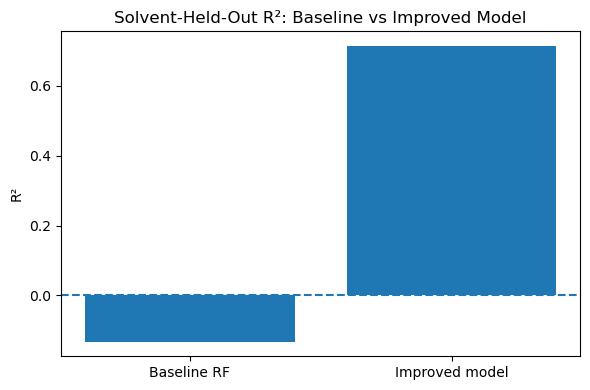

In [15]:
plt.figure(figsize=(6, 4))

plt.bar(
    baseline_vs_improved["Stage"],
    baseline_vs_improved["R2"]
)

plt.ylabel("R²")
plt.title("Solvent-Held-Out R²: Baseline vs Improved Model")
plt.axhline(0, linestyle="--")
plt.tight_layout()

plt.savefig("../outputs/figures/baseline_vs_improved_r2.png", dpi=300)
plt.show()

In [16]:
best_model = ExtraTreesRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Use the same solvent-held-out split indices from Cell 10
best_model.fit(X_train_group, y_train_group_log)

best_pred_log = best_model.predict(X_test_group)
best_pred_raw = (10 ** best_pred_log) - epsilon

best_prediction_results = data.iloc[test_idx_group][[
    "id",
    "cation",
    "anion",
    "solvent",
    "concentration_mol_kg",
    "ionic_conductivity_ms_cm"
]].copy()

best_prediction_results["predicted_conductivity_ms_cm"] = best_pred_raw
best_prediction_results["absolute_error"] = np.abs(
    best_prediction_results["ionic_conductivity_ms_cm"]
    - best_prediction_results["predicted_conductivity_ms_cm"]
)

display(best_prediction_results.head())

best_prediction_results.to_csv(
    "../outputs/metrics/improved_extra_trees_solvent_holdout_predictions.csv",
    index=False
)

,id,cation,anion,solvent,concentration_mol_kg,ionic_conductivity_ms_cm,predicted_conductivity_ms_cm,absolute_error
0,1,K,BETI,AN,0.5,18.348073,25.243246,6.895174
1,2,K,BETI,AN,1.0,40.029239,42.205782,2.176543
2,3,K,BETI,AN,1.5,28.589258,46.863326,18.274067
3,4,K,BETI,AN,2.0,28.614872,26.498030,2.116842
4,5,K,BETI,AN,2.5,37.791487,58.266784,20.475297


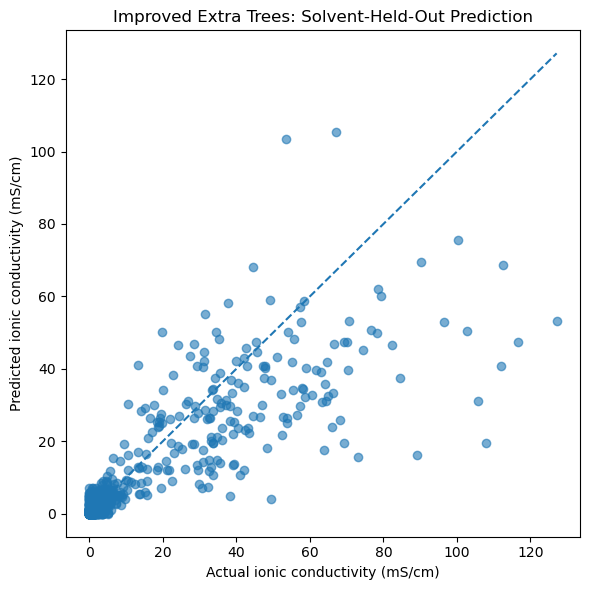

In [17]:
plt.figure(figsize=(6, 6))

plt.scatter(
    best_prediction_results["ionic_conductivity_ms_cm"],
    best_prediction_results["predicted_conductivity_ms_cm"],
    alpha=0.6
)

min_val = min(
    best_prediction_results["ionic_conductivity_ms_cm"].min(),
    best_prediction_results["predicted_conductivity_ms_cm"].min()
)

max_val = max(
    best_prediction_results["ionic_conductivity_ms_cm"].max(),
    best_prediction_results["predicted_conductivity_ms_cm"].max()
)

plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")

plt.xlabel("Actual ionic conductivity (mS/cm)")
plt.ylabel("Predicted ionic conductivity (mS/cm)")
plt.title("Improved Extra Trees: Solvent-Held-Out Prediction")
plt.tight_layout()

plt.savefig("../outputs/figures/improved_extra_trees_solvent_holdout_predicted_vs_actual.png", dpi=300)
plt.show()

In [18]:
def group_error_summary(df, group_col):
    return (
        df.groupby(group_col)
        .agg(
            count=("absolute_error", "count"),
            mean_abs_error=("absolute_error", "mean"),
            median_abs_error=("absolute_error", "median"),
            max_abs_error=("absolute_error", "max")
        )
        .sort_values("mean_abs_error", ascending=False)
    )

improved_error_by_solvent = group_error_summary(best_prediction_results, "solvent")
improved_error_by_anion = group_error_summary(best_prediction_results, "anion")
improved_error_by_cation = group_error_summary(best_prediction_results, "cation")
improved_error_by_concentration = group_error_summary(best_prediction_results, "concentration_mol_kg")

print("Improved error by held-out solvent:")
display(improved_error_by_solvent)

print("Improved error by anion:")
display(improved_error_by_anion)

print("Improved error by cation:")
display(improved_error_by_cation)

print("Improved error by concentration:")
display(improved_error_by_concentration)

improved_error_by_solvent.to_csv("../outputs/metrics/improved_error_by_solvent.csv")
improved_error_by_anion.to_csv("../outputs/metrics/improved_error_by_anion.csv")
improved_error_by_cation.to_csv("../outputs/metrics/improved_error_by_cation.csv")
improved_error_by_concentration.to_csv("../outputs/metrics/improved_error_by_concentration.csv")

Improved error by held-out solvent:


,count,mean_abs_error,median_abs_error,max_abs_error
solvent,,,,
AN,216,15.950232,12.354746,88.484438
EA,213,2.022920,1.423022,10.430596
TEP,215,1.132104,0.899102,5.191397
FEMC,215,0.974327,0.891541,3.211675
EMC,212,0.952148,0.607388,5.083728
EB,215,0.639360,0.380890,4.341519


Improved error by anion:


,count,mean_abs_error,median_abs_error,max_abs_error
anion,,,,
PF6,143,5.647605,1.824569,74.659981
FSI,144,5.011134,1.567459,74.002382
BF4,142,4.463837,0.806725,57.581433
ClO4,142,4.446551,0.928752,88.484438
TFSI,144,4.254655,1.204521,72.805603
DFOB,144,3.240450,1.433168,32.314157
BETI,144,2.727136,0.921833,32.306130
OTf,142,2.221752,0.612143,27.624630
TFA,141,0.612448,0.187220,13.560987


Improved error by cation:


,count,mean_abs_error,median_abs_error,max_abs_error
cation,,,,
K,429,4.538619,1.290490,88.484438
Li,432,3.265276,0.798477,72.805603
Na,425,3.083920,0.920307,57.581433


Improved error by concentration:


,count,mean_abs_error,median_abs_error,max_abs_error
concentration_mol_kg,,,,
3.0,162,4.740392,0.700752,72.805603
2.5,160,4.604124,1.097966,74.659981
1.5,160,4.316673,1.466111,88.484438
2.0,161,3.832316,1.360421,42.230661
3.5,162,3.355145,0.726074,49.721058
4.0,162,2.938634,0.558140,46.938555
1.0,161,2.778127,1.390929,23.689440
0.5,158,2.463217,0.765313,30.329472
